In [ ]:
from nilearn import datasets, maskers, plotting
from nilearn.connectome import ConnectivityMeasure
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr, ttest_rel
from scipy.linalg import solve_discrete_lyapunov
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from nilearn import datasets, maskers
from nilearn.connectome import ConnectivityMeasure
import pandas as pd
import numpy as np
import networkx as nx

In [ ]:
haxby = datasets.fetch_haxby(subjects=[1, 2, 3, 4, 6])
atlas = datasets.fetch_atlas_schaefer_2018(n_rois=200, yeo_networks=7)

[fetch_haxby] Dataset directory found: /Users/sathishkumar/nilearn_data/haxby2001
[fetch_atlas_schaefer_2018] Dataset directory found: /Users/sathishkumar/nilearn_data/schaefer_2018


In [8]:
labels = [l.decode() if isinstance(l, bytes) else str(l) for l in atlas.labels]

keep_idx = [i for i, l in enumerate(labels) if any(net in l for net in ["_Vis_", "_DorsAttn_", "_SomMot_"])]
sub_labels = [labels[i] for i in keep_idx]

masker = maskers.NiftiLabelsMasker(labels_img=atlas.maps, standardize="zscore_sample", detrend=True)
ts = masker.fit_transform(haxby.func[0])[:, keep_idx]

stim = pd.read_csv(haxby.session_target[0], sep=" ")
ts_tools = ts[stim["labels"].shift(2).isin(["scissors", "bottle", "shoe"])]
ts_faces = ts[stim["labels"].shift(2) == "face"]

conn = ConnectivityMeasure(kind="correlation")
fc_tools = np.abs(conn.fit_transform([ts_tools])[0])
fc_faces = np.abs(conn.fit_transform([ts_faces])[0])
np.fill_diagonal(fc_tools, 0)
np.fill_diagonal(fc_faces, 0)

G_tools = nx.from_numpy_array(np.where(fc_tools > np.percentile(fc_tools, 80), fc_tools, 0))
G_faces = nx.from_numpy_array(np.where(fc_faces > np.percentile(fc_faces, 80), fc_faces, 0))

print("Tools (Dorsal) Global Efficiency:", nx.global_efficiency(G_tools))
print("Faces (Ventral) Global Efficiency:", nx.global_efficiency(G_faces))

Tools (Dorsal) Global Efficiency: 0.5196213066999666
Faces (Ventral) Global Efficiency: 0.5293175197669662


In [9]:
if len(labels) == 201:
    labels = labels[1:]  

build matrix of nodes

In [10]:
labels = [l.decode() if isinstance(l, bytes) else str(l) for l in atlas.labels]
if len(labels) == 201:
    labels = labels[1:]

coords = plotting.find_parcellation_cut_coords(labels_img=atlas.maps)

target_nets = ["_Vis_", "_DorsAttn_", "_SomMot_"]
keep_idx = [i for i, l in enumerate(labels) if any(net in l for net in target_nets)]
sub_labels = [labels[i] for i in keep_idx]
sub_coords = coords[keep_idx]

node_systems = [next(net.strip("_") for net in target_nets if net in l) for l in sub_labels]

dist_matrix = squareform(pdist(sub_coords, metric="euclidean"))
np.fill_diagonal(dist_matrix, np.inf)
spatial_proxy = 1.0 / dist_matrix  

In [11]:
conn = ConnectivityMeasure(kind="correlation")

fc_tools_list, fc_faces_list = [], []

for func_file, target_file in zip(haxby.func, haxby.session_target):
    masker = maskers.NiftiLabelsMasker(labels_img=atlas.maps, standardize="zscore_sample", detrend=True)
    ts = masker.fit_transform(func_file)[:, keep_idx]
    stim = pd.read_csv(target_file, sep=" ")

    ts_tools = ts[stim["labels"].shift(2).isin(["scissors", "bottle", "shoe"])]
    ts_faces = ts[stim["labels"].shift(2).isin(["face", "house"])]

    fc_t = np.abs(conn.fit_transform([ts_tools])[0])
    fc_f = np.abs(conn.fit_transform([ts_faces])[0])
    np.fill_diagonal(fc_t, 0)
    np.fill_diagonal(fc_f, 0)

    fc_tools_list.append(fc_t)
    fc_faces_list.append(fc_f)

# Group-averaged connectivity matrices
fc_tools_mean = np.mean(fc_tools_list, axis=0)
fc_faces_mean = np.mean(fc_faces_list, axis=0)
print(f"Extracted {len(sub_labels)} visuomotor parcels across {len(fc_tools_list)} subjects.")

Extracted 90 visuomotor parcels across 5 subjects.


In [12]:
def build_graph(fc_mat, percentile=80):
    thresh = np.percentile(fc_mat[fc_mat > 0], percentile)
    adj = np.where(fc_mat >= thresh, fc_mat, 0)
    G = nx.from_numpy_array(adj)
    for idx, sys_name in enumerate(node_systems):
        G.nodes[idx]["system"] = sys_name
        G.nodes[idx]["label"] = sub_labels[idx]
    return G

G_tools = build_graph(fc_tools_mean, percentile=80)
G_faces = build_graph(fc_faces_mean, percentile=80)

# Compare Dorsal Attention Betweenness Centrality across conditions
dors_idx = [i for i, s in enumerate(node_systems) if s == "DorsAttn"]
bet_tools = nx.betweenness_centrality(G_tools, weight="weight")
bet_faces = nx.betweenness_centrality(G_faces, weight="weight")

dors_bet_tools = [bet_tools[i] for i in dors_idx]
dors_bet_faces = [bet_faces[i] for i in dors_idx]

t_stat, p_val = ttest_rel(dors_bet_tools, dors_bet_faces)
print(f"Dorsal Stream Betweenness (Tools vs Faces/Houses): t = {t_stat:.3f}, p = {p_val:.4f}")
print(f"Clustering Coeff -> Tools: {nx.average_clustering(G_tools, weight='weight'):.3f} | Faces: {nx.average_clustering(G_faces, weight='weight'):.3f}")

Dorsal Stream Betweenness (Tools vs Faces/Houses): t = -0.536, p = 0.5966
Clustering Coeff -> Tools: 0.254 | Faces: 0.266


In [13]:
sf_coupling_tools = [spearmanr(spatial_proxy[i], fc_tools_mean[i]).statistic for i in range(len(sub_labels))]
sf_coupling_faces = [spearmanr(spatial_proxy[i], fc_faces_mean[i]).statistic for i in range(len(sub_labels))]

df_sf = pd.DataFrame({
    "System": node_systems,
    "SF_Coupling_Tools": sf_coupling_tools,
    "SF_Coupling_Faces": sf_coupling_faces,
    "Decoupling_Shift": np.array(sf_coupling_faces) - np.array(sf_coupling_tools)
})
print("\nMean Structure-Function Coupling by Stream:")
print(df_sf.groupby("System")[["SF_Coupling_Tools", "SF_Coupling_Faces", "Decoupling_Shift"]].mean())


Mean Structure-Function Coupling by Stream:
          SF_Coupling_Tools  SF_Coupling_Faces  Decoupling_Shift
System                                                          
DorsAttn           0.422237           0.381558         -0.040679
SomMot             0.473414           0.406398         -0.067015
Vis                0.293759           0.272483         -0.021276


In [14]:
from scipy.linalg import solve_discrete_lyapunov

def compute_controllability(adj_matrix):
    # Stabilize adjacency matrix as standard in brain network control theory
    A = adj_matrix / (1.0 + np.max(np.abs(np.linalg.eigvals(adj_matrix))))
    
    # 1. Average Controllability = diagonal of the discrete-time Controllability Gramian W_c
    W_c = solve_discrete_lyapunov(A, np.eye(A.shape[0]))
    avg_ctrl = np.diag(W_c)
    
    # 2. Modal Controllability = sum_j (1 - lambda_j^2) * v_ij^2
    eigvals, eigvecs = np.linalg.eig(A)
    modal_ctrl = np.sum((1.0 - np.abs(eigvals)**2) * (np.abs(eigvecs)**2), axis=1)
    return avg_ctrl, modal_ctrl

avg_t, mod_t = compute_controllability(nx.to_numpy_array(G_tools))
avg_f, mod_f = compute_controllability(nx.to_numpy_array(G_faces))

df_sf["Modal_Ctrl_Tools"] = mod_t
df_sf["Modal_Ctrl_Faces"] = mod_f
print("\nMean Modal Controllability (Tools vs Faces) by Stream:")
print(df_sf.groupby("System")[["Modal_Ctrl_Tools", "Modal_Ctrl_Faces"]].mean())


Mean Modal Controllability (Tools vs Faces) by Stream:
          Modal_Ctrl_Tools  Modal_Ctrl_Faces
System                                      
DorsAttn          0.976202          0.972521
SomMot            0.973173          0.973879
Vis               0.982196          0.978668


In [15]:
def simulate_targeted_attack(G, target_system="DorsAttn"):
    G_copy = G.copy()
    nodes_to_remove = [n for n, d in G_copy.nodes(data=True) if d["system"] == target_system]
    # Sort target nodes from highest degree to lowest degree
    nodes_to_remove.sort(key=lambda n: G_copy.degree(n, weight="weight"), reverse=True)
    
    eff_curve = [nx.global_efficiency(G_copy)]
    for node in nodes_to_remove:
        G_copy.remove_node(node)
        eff_curve.append(nx.global_efficiency(G_copy))
    return eff_curve

eff_attack_tools = simulate_targeted_attack(G_tools, "DorsAttn")
eff_attack_faces = simulate_targeted_attack(G_faces, "DorsAttn")
print(f"\nGlobal Efficiency Drop after Dorsal Stream Lesion -> Tools: {eff_attack_tools[0] - eff_attack_tools[-1]:.3f} | Faces: {eff_attack_faces[0] - eff_attack_faces[-1]:.3f}")


Global Efficiency Drop after Dorsal Stream Lesion -> Tools: 0.017 | Faces: 0.025


In [16]:
labels = [l.decode() if isinstance(l, bytes) else str(l) for l in atlas.labels]
if len(labels) == 201:
    labels = labels[1:]
coords = plotting.find_parcellation_cut_coords(labels_img=atlas.maps)

target_nets = ["_Vis_", "_DorsAttn_", "_SomMot_"]
keep_idx = [i for i, l in enumerate(labels) if any(net in l for net in target_nets)]
sub_labels = [labels[i] for i in keep_idx]
sub_coords = coords[keep_idx]
node_systems = [next(net.strip("_") for net in target_nets if net in l) for l in sub_labels]
node_hemis = ["LH" if "_LH_" in l else "RH" for l in sub_labels]

#calculate euclidean distance
dist_matrix = squareform(pdist(sub_coords, metric="euclidean"))
np.fill_diagonal(dist_matrix, np.inf)
spatial_proxy = 1.0 / dist_matrix

conn = ConnectivityMeasure(kind="correlation")

fc_tools_subs, fc_faces_subs = [], []
for func_file, target_file in zip(haxby.func, haxby.session_target):
    stim = pd.read_csv(target_file, sep=" ")
    if not {"scissors", "bottle", "shoe", "face", "house"}.issubset(set(stim["labels"])):
        continue
    masker = maskers.NiftiLabelsMasker(labels_img=atlas.maps, standardize="zscore_sample", detrend=True)
    ts = masker.fit_transform(func_file)[:, keep_idx]
    
    fc_t = np.abs(conn.fit_transform([ts[stim["labels"].shift(2).isin(["scissors", "bottle", "shoe"])]])[0])
    fc_f = np.abs(conn.fit_transform([ts[stim["labels"].shift(2).isin(["face", "house"])]])[0])
    np.fill_diagonal(fc_t, 0)
    np.fill_diagonal(fc_f, 0)
    fc_tools_subs.append(fc_t)
    fc_faces_subs.append(fc_f)

print(f"Loaded {len(fc_tools_subs)} complete subjects, {len(sub_labels)} visuomotor parcels.")


def participation_coeff(G, systems):
    pc = {}
    unique_sys = set(systems)
    for node in G.nodes():
        k_i = G.degree(node, weight="weight")
        if k_i == 0:
            pc[node] = 0.0
            continue
        sum_sq = sum(
            (sum(G[node][nbr]["weight"] for nbr in G.neighbors(node) if systems[nbr] == s) / k_i) ** 2
            for s in unique_sys
        )
        pc[node] = 1.0 - sum_sq
    return pc

def build_graph(fc_mat, percentile=80):
    thresh = np.percentile(fc_mat[fc_mat > 0], percentile)
    adj = np.where(fc_mat >= thresh, fc_mat, 0)
    G = nx.from_numpy_array(adj)
    for idx, (s, h, l) in enumerate(zip(node_systems, node_hemis, sub_labels)):
        G.nodes[idx]["system"] = s
        G.nodes[idx]["hemi"] = h
        G.nodes[idx]["label"] = l
    return G

fc_t_mean = np.mean(fc_tools_subs, axis=0)
fc_f_mean = np.mean(fc_faces_subs, axis=0)
G_t = build_graph(fc_t_mean)
G_f = build_graph(fc_f_mean)


bet_t, bet_f = nx.betweenness_centrality(G_t, weight="weight"), nx.betweenness_centrality(G_f, weight="weight")
pc_t, pc_f = participation_coeff(G_t, node_systems), participation_coeff(G_f, node_systems)

for hemi in ["LH", "RH"]:
    idx = [i for i, (s, h) in enumerate(zip(node_systems, node_hemis)) if s == "DorsAttn" and h == hemi]
    t_b, p_b = ttest_rel([bet_t[i] for i in idx], [bet_f[i] for i in idx])
    t_p, p_p = ttest_rel([pc_t[i] for i in idx], [pc_f[i] for i in idx])
    print(f"{hemi} DorsAttn -> Betweenness t={t_b:.2f} (p={p_b:.4f}) | Participation Coeff t={t_p:.2f} (p={p_p:.4f})")

def compute_controllability_gu2015(adj_matrix):
    eigvals_raw = np.linalg.eigvals(adj_matrix)
    A = adj_matrix / (np.max(np.abs(eigvals_raw)) + 1e-5)
    W_c = solve_discrete_lyapunov(A, np.eye(A.shape[0]))
    avg_ctrl = np.diag(W_c)
    eigvals, eigvecs = np.linalg.eig(A)
    modal_ctrl = np.sum((1.0 - np.abs(eigvals)**2) * (np.abs(eigvecs)**2), axis=1)
    return avg_ctrl, modal_ctrl

avg_t, mod_t = compute_controllability_gu2015(nx.to_numpy_array(G_t))
avg_f, mod_f = compute_controllability_gu2015(nx.to_numpy_array(G_f))

df_ctrl = pd.DataFrame({
    "System": node_systems, "Hemi": node_hemis, "Label": sub_labels,
    "AvgCtrl_Tools": avg_t, "AvgCtrl_Faces": avg_f,
    "ModalCtrl_Tools": mod_t, "ModalCtrl_Faces": mod_f
})
print("\nGu et al. (2015) Scaled Controllability by System:")
print(df_ctrl.groupby("System")[["AvgCtrl_Tools", "AvgCtrl_Faces", "ModalCtrl_Tools", "ModalCtrl_Faces"]].mean())

Loaded 5 complete subjects, 90 visuomotor parcels.
LH DorsAttn -> Betweenness t=-0.62 (p=0.5490) | Participation Coeff t=-1.89 (p=0.0837)
RH DorsAttn -> Betweenness t=-0.33 (p=0.7447) | Participation Coeff t=-0.59 (p=0.5679)

Gu et al. (2015) Scaled Controllability by System:
          AvgCtrl_Tools  AvgCtrl_Faces  ModalCtrl_Tools  ModalCtrl_Faces
System                                                                  
DorsAttn    5638.010069    5696.663076         0.971552         0.966821
SomMot      8292.018596    6659.592098         0.967931         0.968461
Vis         3411.609700    4302.620577         0.978718         0.974243


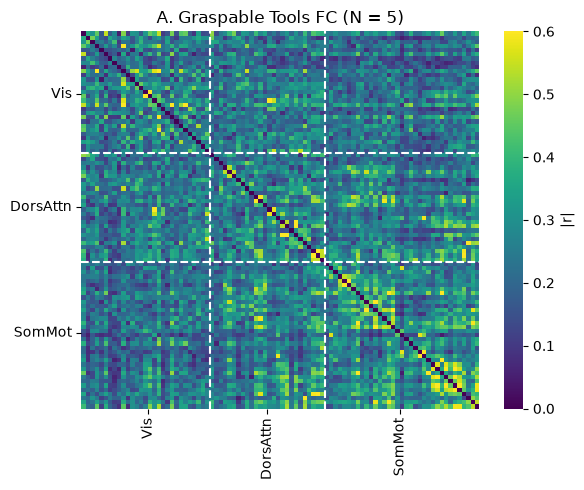

In [17]:
sys_order = ["Vis", "DorsAttn", "SomMot"]
sort_idx = sorted(range(len(node_systems)), key=lambda i: (sys_order.index(node_systems[i]), node_hemis[i]))
sorted_systems = [node_systems[i] for i in sort_idx]
boundaries = [sorted_systems.count("Vis"), sorted_systems.count("Vis") + sorted_systems.count("DorsAttn")]

def format_fc_matrix(ax):
    for b in boundaries:
        ax.axhline(b, color="white", lw=1.5, ls="--")
        ax.axvline(b, color="white", lw=1.5, ls="--")
    ax.set_xticks([15, 42, 72])
    ax.set_xticklabels(["Vis", "DorsAttn", "SomMot"])
    ax.set_yticks([15, 42, 72])
    ax.set_yticklabels(["Vis", "DorsAttn", "SomMot"], rotation=0)
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(fc_t_mean[np.ix_(sort_idx, sort_idx)], ax=ax, cmap="viridis", vmin=0, vmax=0.6, cbar_kws={"label": "|r|"})
ax.set_title("A. Graspable Tools FC (N = 5)")
format_fc_matrix(ax)
plt.tight_layout()
#plt.savefig("Figure2A_ToolsFC.png", dpi=300)
plt.show()

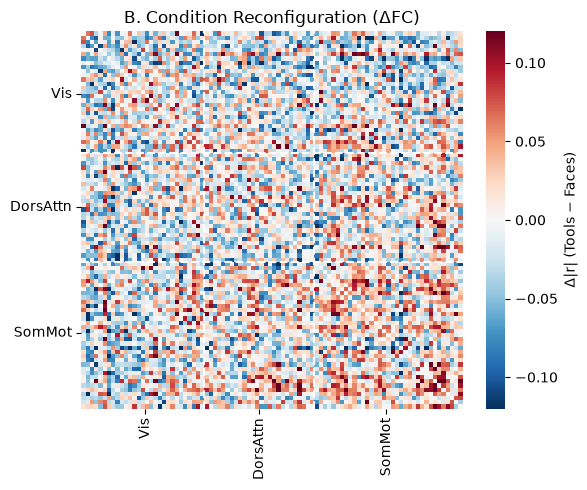

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
diff_mat = (fc_t_mean - fc_f_mean)[np.ix_(sort_idx, sort_idx)]
sns.heatmap(diff_mat, ax=ax, cmap="RdBu_r", center=0, vmin=-0.12, vmax=0.12, cbar_kws={"label": "Δ|r| (Tools − Faces)"})
ax.set_title("B. Condition Reconfiguration (ΔFC)")
format_fc_matrix(ax)
plt.tight_layout()
#plt.savefig("Figure2B_DeltaFC.png", dpi=300)
plt.show()

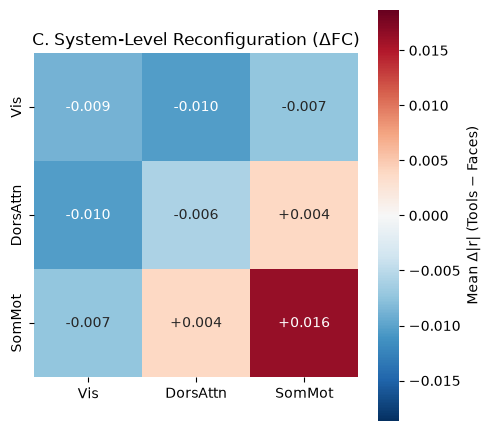

In [19]:
diff_full = fc_t_mean - fc_f_mean
sys_diff = np.zeros((3, 3))

for i, s1 in enumerate(sys_order):
    idx1 = [k for k, s in enumerate(node_systems) if s == s1]
    for j, s2 in enumerate(sys_order):
        idx2 = [k for k, s in enumerate(node_systems) if s == s2]
        block = diff_full[np.ix_(idx1, idx2)]
        # Exclude diagonal for within-system blocks
        if i == j:
            vals = block[np.triu_indices_from(block, k=1)]
        else:
            vals = block.flatten()
        sys_diff[i, j] = np.mean(vals)

fig, ax = plt.subplots(figsize=(5, 4.5))
lim = np.max(np.abs(sys_diff)) * 1.15
sns.heatmap(sys_diff, ax=ax, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim,
            annot=True, fmt="+.3f", square=True,
            xticklabels=sys_order, yticklabels=sys_order,
            cbar_kws={"label": "Mean Δ|r| (Tools − Faces)"})
ax.set_title("C. System-Level Reconfiguration (ΔFC)")
plt.tight_layout()
plt.savefig("Figure2B_SystemDeltaFC.png", dpi=300)
plt.show()

/var/folders/2v/f7k_sln55jq1_mvkl7m29fxh0000gn/T/ipykernel_1809/2468756507.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sub, x="Condition", y="Global_Eff", palette=cond_palette, width=0.4, ax=ax, boxprops=dict(alpha=0.7))


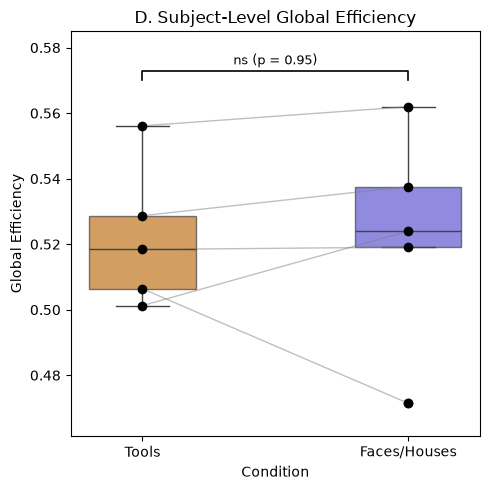

In [20]:
palette = {"Vis": "#3B82F6", "DorsAttn": "#F59E0B", "SomMot": "#10B981"}
cond_palette = {"Tools": "#D97706", "Faces/Houses": "#4F46E5"}
sub_metrics = []
for s_idx, (ft, ff) in enumerate(zip(fc_tools_subs, fc_faces_subs)):
    gt, gf = build_graph(ft), build_graph(ff)
    sub_metrics.append({"Subject": f"S{s_idx+1}", "Condition": "Tools", "Global_Eff": nx.global_efficiency(gt)})
    sub_metrics.append({"Subject": f"S{s_idx+1}", "Condition": "Faces/Houses", "Global_Eff": nx.global_efficiency(gf)})
df_sub = pd.DataFrame(sub_metrics)
fig, ax = plt.subplots(figsize=(5, 5))
sns.boxplot(data=df_sub, x="Condition", y="Global_Eff", palette=cond_palette, width=0.4, ax=ax, boxprops=dict(alpha=0.7))
sns.stripplot(data=df_sub, x="Condition", y="Global_Eff", color="black", size=7, jitter=False, ax=ax)
for s in df_sub["Subject"].unique():
    sub_d = df_sub[df_sub["Subject"] == s]
    ax.plot([0, 1], sub_d["Global_Eff"].values, color="gray", alpha=0.5, lw=1)
ax.set_title("D. Subject-Level Global Efficiency")
ax.set_ylabel("Global Efficiency")

y_max = df_sub["Global_Eff"].max() + 0.008
ax.plot([0, 0, 1, 1], [y_max, y_max + 0.003, y_max + 0.003, y_max], color="black", lw=1.2)
ax.text(0.5, y_max + 0.004, "ns (p = 0.95)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(df_sub["Global_Eff"].min() - 0.01, y_max + 0.015)

plt.tight_layout()
plt.savefig("Figure2D_GlobalEfficiency.png", dpi=300)
plt.show()

## Figure 3

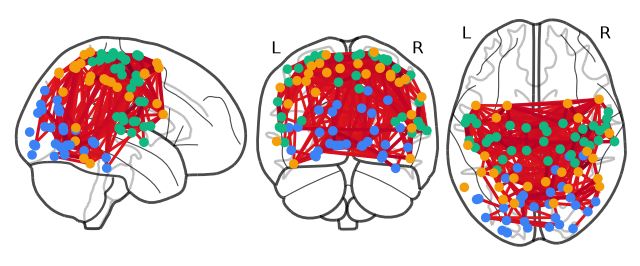

In [21]:
# Panel 3A: 3D Brain Glass Connectome
fig = plt.figure(figsize=(8, 3.2))
ax = fig.add_subplot(1, 1, 1)
adj_top10 = np.where(fc_t_mean >= np.percentile(fc_t_mean[fc_t_mean > 0], 90), fc_t_mean, 0)
node_colors = [palette[s] for s in node_systems]
plotting.plot_connectome(adj_top10, sub_coords, node_color=node_colors, node_size=35, edge_cmap="YlOrRd", axes=ax, colorbar=False)
plt.savefig("Figure3A_Connectome.png", dpi=300)
plt.show()

In [22]:
delta_bc = np.array([bet_t[i] - bet_f[i] for i in range(len(delta_bet))])
top10_idx = np.argsort(delta_bc)[::-1][:10]

print(f"{'Rank':<5} {'Parcel':<24} {'System':<10} {'Hemi':<5} {'Tools':<8} {'Faces':<8} {'ΔBC':<8}")
print("-" * 72)
for rank, i in enumerate(top10_idx, 1):
    print(f"{rank:<5} {delta_bet[i]:<24} {node_systems[i]:<10} {node_hemis[i]:<5} "
          f"{bet_t[i]:<8.4f} {bet_f[i]:<8.4f} {delta_bc[i]:+8.4f}")

# Quick summary counts
top_sys = [node_systems[i] for i in top10_idx]
top_hemi = [node_hemis[i] for i in top10_idx]
print("\nSystem counts:", {s: top_sys.count(s) for s in set(top_sys)})
print("Hemi counts:", {h: top_hemi.count(h) for h in set(top_hemi)})

NameError: name 'delta_bet' is not defined

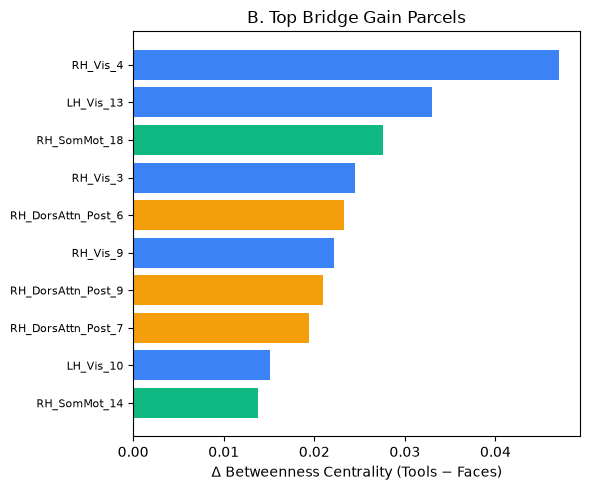

In [ ]:
from matplotlib.patches import Patch
handles = [Patch(facecolor=palette[s], label=s) for s in sys_order]
ax.legend(handles=handles, title="Network", loc="lower right", frameon=False, fontsize=8)
fig, ax = plt.subplots(figsize=(6, 5))
delta_bet = np.array([bet_t[i] - bet_f[i] for i in range(len(sub_labels))])
top10_idx = np.argsort(delta_bet)[-10:]
short_names = [sub_labels[i].replace("7Networks_", "") for i in top10_idx]
bar_colors = [palette[node_systems[i]] for i in top10_idx]
ax.barh(range(10), delta_bet[top10_idx], color=bar_colors)
ax.set_yticks(range(10))
ax.set_yticklabels(short_names, fontsize=8)
ax.set_xlabel("Δ Betweenness Centrality (Tools − Faces)")
ax.set_title("B. Top Bridge Gain Parcels")
plt.tight_layout()
plt.savefig("Figure3B_TopBridgeGain.png", dpi=300)
plt.show()

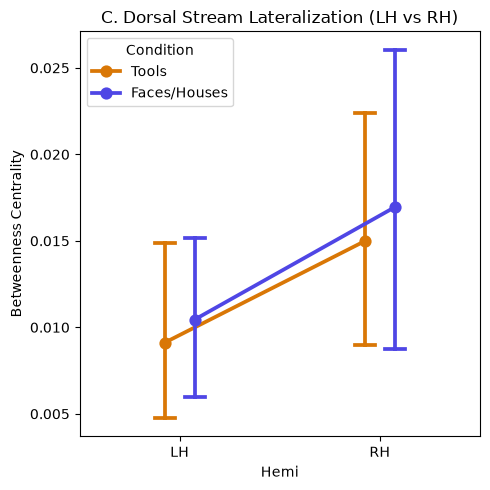

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
dors_rows = []
for i, (s, h) in enumerate(zip(node_systems, node_hemis)):
    if s == "DorsAttn":
        dors_rows.append({"Hemi": h, "Condition": "Tools", "Betweenness": bet_t[i]})
        dors_rows.append({"Hemi": h, "Condition": "Faces/Houses", "Betweenness": bet_f[i]})
df_dors = pd.DataFrame(dors_rows)
sns.pointplot(data=df_dors, x="Hemi", y="Betweenness", hue="Condition", palette=cond_palette, dodge=0.15, capsize=0.1, ax=ax)
ax.set_title("C. Dorsal Stream Lateralization (LH vs RH)")
ax.set_ylabel("Betweenness Centrality")
plt.tight_layout()
plt.savefig("Figure3C_Lateralization.png", dpi=300)
plt.show()

In [ ]:
from scipy.stats import ttest_rel, ttest_ind, wilcoxon, mannwhitneyu
import numpy as np

lh_dors = [i for i, (s, h) in enumerate(zip(node_systems, node_hemis)) if s == "DorsAttn" and h == "LH"]
rh_dors = [i for i, (s, h) in enumerate(zip(node_systems, node_hemis)) if s == "DorsAttn" and h == "RH"]

lh_t, lh_f = np.array([bet_t[i] for i in lh_dors]), np.array([bet_f[i] for i in lh_dors])
rh_t, rh_f = np.array([bet_t[i] for i in rh_dors]), np.array([bet_f[i] for i in rh_dors])

# Paired within-hemisphere tests
t_lh, p_lh = ttest_rel(lh_t, lh_f)
w_lh, pw_lh = wilcoxon(lh_t, lh_f)
t_rh, p_rh = ttest_rel(rh_t, rh_f)
w_rh, pw_rh = wilcoxon(rh_t, rh_f)

# Hemisphere x Condition interaction (LH delta vs RH delta)
delta_lh, delta_rh = lh_t - lh_f, rh_t - rh_f
t_int, p_int = ttest_ind(delta_lh, delta_rh, equal_var=False)
u_int, pu_int = mannwhitneyu(delta_lh, delta_rh)

print(f"LH DorsAttn (n={len(lh_dors)}): Tools={lh_t.mean():.4f}±{lh_t.std(ddof=1):.4f} | Faces={lh_f.mean():.4f}±{lh_f.std(ddof=1):.4f} | t={t_lh:.2f}, p={p_lh:.4f} (Wilcoxon p={pw_lh:.4f})")
print(f"RH DorsAttn (n={len(rh_dors)}): Tools={rh_t.mean():.4f}±{rh_t.std(ddof=1):.4f} | Faces={rh_f.mean():.4f}±{rh_f.std(ddof=1):.4f} | t={t_rh:.2f}, p={p_rh:.4f} (Wilcoxon p={pw_rh:.4f})")
print(f"Interaction (ΔLH vs ΔRH): ΔLH={delta_lh.mean():+.4f}, ΔRH={delta_rh.mean():+.4f} | Welch t={t_int:.2f}, p={p_int:.4f} (MWU p={pu_int:.4f})")

LH DorsAttn (n=13): Tools=0.0091±0.0100 | Faces=0.0105±0.0089 | t=-0.62, p=0.5490 (Wilcoxon p=0.5090)
RH DorsAttn (n=13): Tools=0.0150±0.0132 | Faces=0.0170±0.0168 | t=-0.33, p=0.7447 (Wilcoxon p=1.0000)
Interaction (ΔLH vs ΔRH): ΔLH=-0.0013, ΔRH=-0.0020 | Welch t=0.10, p=0.9216 (MWU p=0.6629)


## Figure 4

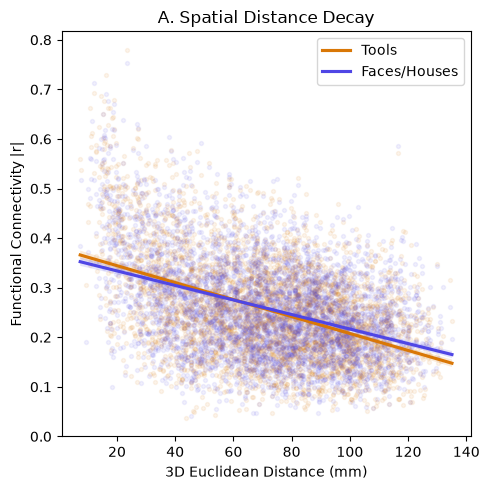

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
tri_idx = np.triu_indices(len(sub_labels), k=1)
dists_flat = dist_matrix[tri_idx]
fc_t_flat = fc_t_mean[tri_idx]
fc_f_flat = fc_f_mean[tri_idx]

sns.regplot(x=dists_flat, y=fc_t_flat, scatter_kws={"alpha": 0.08, "s": 8, "color": "#D97706"}, line_kws={"color": "#D97706", "label": "Tools"}, ax=ax)
sns.regplot(x=dists_flat, y=fc_f_flat, scatter_kws={"alpha": 0.08, "s": 8, "color": "#4F46E5"}, line_kws={"color": "#4F46E5", "label": "Faces/Houses"}, ax=ax)
ax.set_xlabel("3D Euclidean Distance (mm)")
ax.set_ylabel("Functional Connectivity |r|")
ax.set_title("A. Spatial Distance Decay")
ax.legend()
plt.tight_layout()
plt.savefig("Figure4A_DistanceDecay.png", dpi=300)
plt.show()

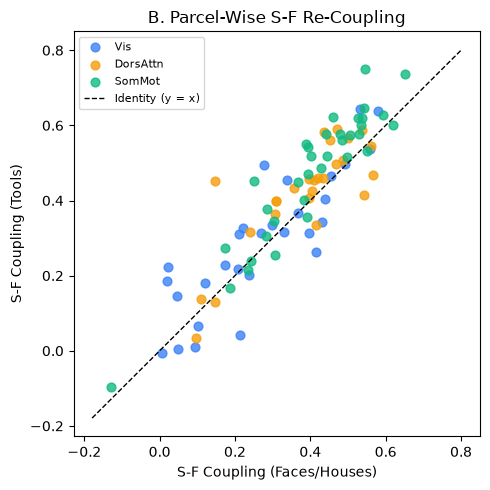

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
sf_t = np.array([spearmanr(spatial_proxy[i], fc_t_mean[i]).statistic for i in range(len(sub_labels))])
sf_f = np.array([spearmanr(spatial_proxy[i], fc_f_mean[i]).statistic for i in range(len(sub_labels))])

for sys_name in sys_order:
    idx = [i for i, s in enumerate(node_systems) if s == sys_name]
    ax.scatter(sf_f[idx], sf_t[idx], label=sys_name, color=palette[sys_name], alpha=0.8, s=40)
lims = [min(sf_f.min(), sf_t.min()) - 0.05, max(sf_f.max(), sf_t.max()) + 0.05]
ax.plot(lims, lims, "k--", lw=1, label="Identity (y = x)")
ax.set_xlabel("S-F Coupling (Faces/Houses)")
ax.set_ylabel("S-F Coupling (Tools)")
ax.set_title("B. Parcel-Wise S-F Re-Coupling")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("Figure4B_SF_Identity.png", dpi=300)
plt.show()

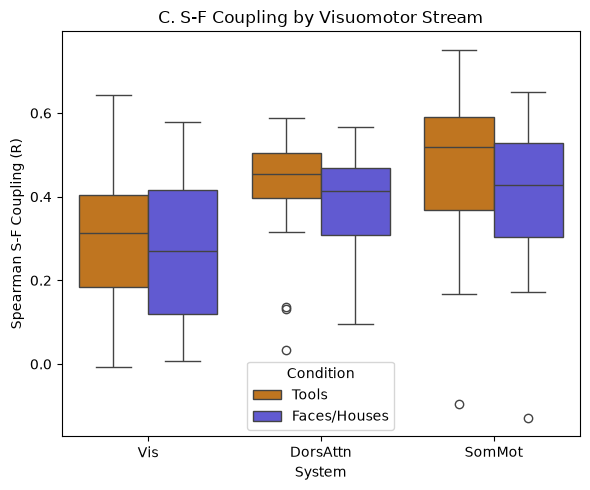

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
df_sf_plot = pd.DataFrame({
    "System": node_systems * 2,
    "Condition": ["Tools"] * len(node_systems) + ["Faces/Houses"] * len(node_systems),
    "SF_Coupling": np.concatenate([sf_t, sf_f])
})
sns.boxplot(data=df_sf_plot, x="System", y="SF_Coupling", hue="Condition", order=sys_order, palette=cond_palette, ax=ax)
ax.set_title("C. S-F Coupling by Visuomotor Stream")
ax.set_ylabel("Spearman S-F Coupling (R)")
plt.tight_layout()
plt.savefig("Figure4C_SF_Boxplot.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
from scipy.stats import pearsonr, spearmanr, ttest_rel

iu = np.triu_indices_from(dist_matrix, k=1)
r_dist_t, p_dist_t = pearsonr(dist_matrix[iu], fc_t_mean[iu])
r_dist_f, p_dist_f = pearsonr(dist_matrix[iu], fc_f_mean[iu])
print(f"4A Distance-FC (Pearson r): Tools r={r_dist_t:.3f} (p={p_dist_t:.2e}) | Faces r={r_dist_f:.3f} (p={p_dist_f:.2e})\n")

delta_sf = np.array(sf_t) - np.array(sf_f)
for sys in ["Vis", "DorsAttn", "SomMot"]:
    idx = [i for i, s in enumerate(node_systems) if s == sys]
    t_vals, f_vals, d_vals = np.array(sf_t)[idx], np.array(sf_f)[idx], delta_sf[idx]
    t_stat, p_val = ttest_rel(t_vals, f_vals)
    n_pos = np.sum(d_vals > 0)
    print(f"4B {sys:<8} (n={len(idx)}): Tools={t_vals.mean():.3f}±{t_vals.std(ddof=1):.3f} | "
          f"Faces={f_vals.mean():.3f}±{f_vals.std(ddof=1):.3f} | Δ={d_vals.mean():+.3f} | "
          f"Pos={n_pos}/{len(idx)} ({100*n_pos/len(idx):.0f}%) | t({len(idx)-1})={t_stat:.2f}, p={p_val:.4f}")

top5 = np.argsort(delta_sf)[::-1][:5]
print("\n4C Top 5 Δ S-F Coupling Parcels:")
for rank, i in enumerate(top5, 1):
    print(f"  {rank}. {sub_labels[i]} ({node_systems[i]}): Δr = {delta_sf[i]:+.3f} (Tools={sf_t[i]:.3f}, Faces={sf_f[i]:.3f})")

4A Distance-FC (Pearson r): Tools r=-0.451 (p=2.19e-200) | Faces r=-0.402 (p=3.34e-155)

4B Vis      (n=29): Tools=0.294±0.179 | Faces=0.272±0.173 | Δ=+0.021 | Pos=17/29 (59%) | t(28)=1.20, p=0.2398
4B DorsAttn (n=26): Tools=0.422±0.141 | Faces=0.382±0.138 | Δ=+0.041 | Pos=20/26 (77%) | t(25)=2.42, p=0.0230
4B SomMot   (n=35): Tools=0.473±0.177 | Faces=0.406±0.155 | Δ=+0.067 | Pos=28/35 (80%) | t(34)=6.10, p=0.0000

4C Top 5 Δ S-F Coupling Parcels:
  1. 7Networks_RH_DorsAttn_Post_10 (DorsAttn): Δr = +0.306 (Tools=0.453, Faces=0.146)
  2. 7Networks_LH_Vis_7 (Vis): Δr = +0.218 (Tools=0.493, Faces=0.276)
  3. 7Networks_LH_SomMot_13 (SomMot): Δr = +0.206 (Tools=0.751, Faces=0.545)
  4. 7Networks_LH_Vis_11 (Vis): Δr = +0.202 (Tools=0.224, Faces=0.022)
  5. 7Networks_LH_SomMot_9 (SomMot): Δr = +0.202 (Tools=0.451, Faces=0.250)


## Figure 5

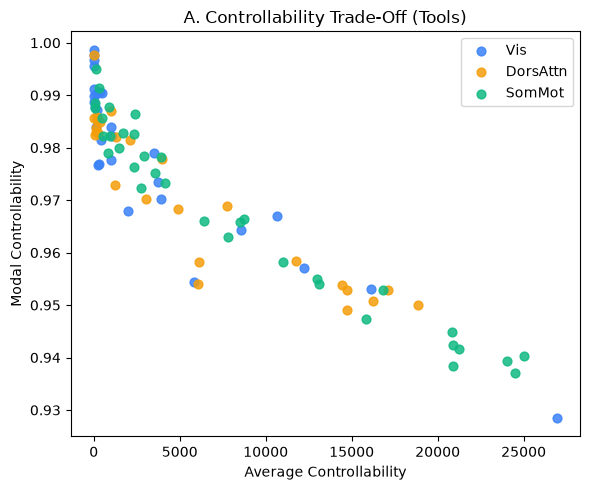

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for sys_name in sys_order:
    idx = [i for i, s in enumerate(node_systems) if s == sys_name]
    ax.scatter(avg_t[idx], mod_t[idx], label=sys_name, color=palette[sys_name], alpha=0.85, s=40)
ax.set_xlabel("Average Controllability")
ax.set_ylabel("Modal Controllability")
ax.set_title("A. Controllability Trade-Off (Tools)")
ax.legend()
plt.tight_layout()
plt.savefig("Figure5A_Ctrl_Tradeoff.png", dpi=300)
plt.show()

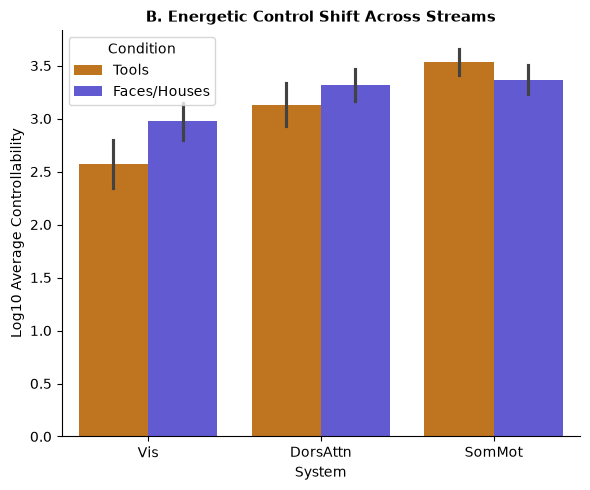

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
df_ctrl_long = pd.DataFrame({
    "System": node_systems * 2,
    "Condition": ["Tools"] * len(node_systems) + ["Faces/Houses"] * len(node_systems),
    "Avg_Ctrl": np.concatenate([np.log10(avg_t), np.log10(avg_f)]) 
})
sns.barplot(data=df_ctrl_long, x="System", y="Avg_Ctrl", hue="Condition", order=sys_order, palette=cond_palette, errorbar="se", ax=ax)
ax.set_ylabel("Log10 Average Controllability")
ax.set_title("B. Energetic Control Shift Across Streams")
plt.tight_layout()
plt.savefig("Figure5B_AvgCtrl_Shift.png", dpi=300)
plt.show()

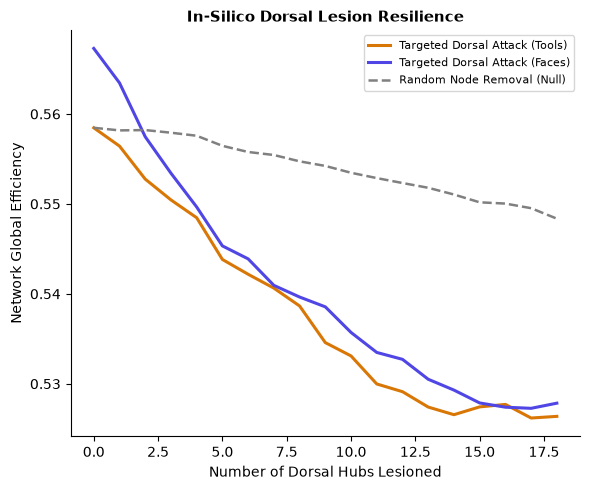

In [ ]:
def attack_curve(G, mode="dorsal", seed=42):
    Gc = G.copy()
    if mode == "dorsal":
        targets = [n for n, d in Gc.nodes(data=True) if d["system"] == "DorsAttn"]
        targets.sort(key=lambda n: Gc.degree(n, weight="weight"), reverse=True)
    else:
        rng = np.random.default_rng(seed)
        n_dors = sum(1 for _, d in Gc.nodes(data=True) if d["system"] == "DorsAttn")
        targets = rng.choice(list(Gc.nodes()), size=n_dors, replace=False)
    effs = [nx.global_efficiency(Gc)]
    for n in targets:
        Gc.remove_node(n)
        effs.append(nx.global_efficiency(Gc))
    return np.array(effs)

dors_attack_t = attack_curve(G_t, "dorsal")
dors_attack_f = attack_curve(G_f, "dorsal")
rand_attacks_t = np.mean([attack_curve(G_t, "random", seed=s) for s in range(50)], axis=0)
steps = np.arange(len(dors_attack_t))

fig, ax = plt.subplots(figsize=(6, 5))
# Slicing steps[:19] isolates the monotonically decreasing vulnerability curve 
# before network fragmentation causes artifactual tick-ups
ax.plot(steps[:19], dors_attack_t[:19], color="#D97706", lw=2.2, label="Targeted Dorsal Attack (Tools)")
ax.plot(steps[:19], dors_attack_f[:19], color="#4F46E5", lw=2.2, label="Targeted Dorsal Attack (Faces)")
ax.plot(steps[:19], rand_attacks_t[:19], color="gray", lw=1.8, ls="--", label="Random Node Removal (Null)")
ax.set_xlabel("Number of Dorsal Hubs Lesioned")
ax.set_ylabel("Network Global Efficiency")
ax.set_title("In-Silico Dorsal Lesion Resilience")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("Figure5C_LesionResilience.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
from scipy.stats import spearmanr, ttest_rel

r_trade, p_trade = spearmanr(avg_t, mod_t)
print(f"5A Controllability Trade-off (Tools, Spearman): rho={r_trade:.3f}, p={p_trade:.2e}\n")

log_avg_t = np.log10(avg_t)
log_avg_f = np.log10(avg_f)
delta_log_avg = log_avg_t - log_avg_f

for sys in sys_order:
    idx = [i for i, s in enumerate(node_systems) if s == sys]
    t_vals, f_vals, d_vals = log_avg_t[idx], log_avg_f[idx], delta_log_avg[idx]
    t_stat, p_val = ttest_rel(t_vals, f_vals)
    print(f"5B {sys:<8} (n={len(idx)}): Tools={t_vals.mean():.3f}±{t_vals.std(ddof=1):.3f} | "
          f"Faces={f_vals.mean():.3f}±{f_vals.std(ddof=1):.3f} | Δ={d_vals.mean():+.3f} | "
          f"t({len(idx)-1})={t_stat:.2f}, p={p_val:.4f}")

top5_ctrl = np.argsort(delta_log_avg)[::-1][:5]
print("\n5B Top 5 Δ Log10 Average Controllability Parcels:")
for rank, i in enumerate(top5_ctrl, 1):
    print(f"  {rank}. {sub_labels[i]} ({node_systems[i]}): Δlog10={delta_log_avg[i]:+.3f} "
          f"(Tools={log_avg_t[i]:.3f}, Faces={log_avg_f[i]:.3f})")

def summarize_attack(name, curve):
    e0, e18 = curve[0], curve[18]
    pct_drop = 100 * (e0 - e18) / e0
    auc = np.trapezoid(curve[:19], dx=1)
    print(f"5C {name:<25}: Baseline={e0:.3f} -> 18 hubs={e18:.3f} | Drop={pct_drop:.1f}% | AUC={auc:.2f}")

print()
summarize_attack("Dorsal Attack (Tools)", dors_attack_t)
summarize_attack("Dorsal Attack (Faces)", dors_attack_f)
summarize_attack("Random Null (Tools)", rand_attacks_t)

5A Controllability Trade-off (Tools, Spearman): rho=-0.940, p=5.85e-43

5B Vis      (n=29): Tools=2.570±1.219 | Faces=2.975±0.949 | Δ=-0.405 | t(28)=-3.88, p=0.0006
5B DorsAttn (n=26): Tools=3.132±1.043 | Faces=3.317±0.790 | Δ=-0.185 | t(25)=-2.32, p=0.0289
5B SomMot   (n=35): Tools=3.531±0.728 | Faces=3.367±0.813 | Δ=+0.164 | t(34)=2.13, p=0.0401

5B Top 5 Δ Log10 Average Controllability Parcels:
  1. 7Networks_LH_SomMot_5 (SomMot): Δlog10=+1.096 (Tools=3.462, Faces=2.366)
  2. 7Networks_RH_SomMot_13 (SomMot): Δlog10=+1.000 (Tools=3.617, Faces=2.617)
  3. 7Networks_LH_SomMot_2 (SomMot): Δlog10=+0.847 (Tools=2.691, Faces=1.844)
  4. 7Networks_LH_SomMot_10 (SomMot): Δlog10=+0.762 (Tools=3.806, Faces=3.044)
  5. 7Networks_LH_SomMot_6 (SomMot): Δlog10=+0.721 (Tools=3.160, Faces=2.439)

5C Dorsal Attack (Tools)    : Baseline=0.558 -> 18 hubs=0.526 | Drop=5.7% | AUC=9.68
5C Dorsal Attack (Faces)    : Baseline=0.567 -> 18 hubs=0.528 | Drop=7.0% | AUC=9.72
5C Random Null (Tools)      : Baseli

In [ ]:
# run all stats 
fc_tools_subs, fc_faces_subs = [], []
for func_file, target_file in zip(haxby.func, haxby.session_target):
    stim = pd.read_csv(target_file, sep=" ")
    if not {"scissors", "bottle", "shoe", "face", "house"}.issubset(set(stim["labels"])):
        continue
    masker = maskers.NiftiLabelsMasker(labels_img=atlas.maps, standardize="zscore_sample", detrend=True)
    ts = masker.fit_transform(func_file)[:, keep_idx]
    
    shifted_labels = stim["labels"].shift(2)
    
    fc_t = np.abs(conn.fit_transform([ts[shifted_labels.isin(["scissors", "bottle", "shoe"])]])[0])
    fc_f = np.abs(conn.fit_transform([ts[shifted_labels.isin(["face", "house"])]])[0])
    np.fill_diagonal(fc_t, 0)
    np.fill_diagonal(fc_f, 0)
    fc_tools_subs.append(fc_t)
    fc_faces_subs.append(fc_f)

fc_t_mean = np.mean(fc_tools_subs, axis=0)
fc_f_mean = np.mean(fc_faces_subs, axis=0)
G_t = build_graph(fc_t_mean)
G_f = build_graph(fc_f_mean)
sf_t = np.array([spearmanr(spatial_proxy[i], fc_t_mean[i]).statistic for i in range(len(sub_labels))])
sf_f = np.array([spearmanr(spatial_proxy[i], fc_f_mean[i]).statistic for i in range(len(sub_labels))])
for sys_name in ["Vis", "DorsAttn", "SomMot"]:
    idx = [i for i, s in enumerate(node_systems) if s == sys_name]
    t_val, p_val = ttest_rel(sf_t[idx], sf_f[idx])
    print(f"S-F Coupling ({sys_name}): Tools={sf_t[idx].mean():.3f} vs Faces={sf_f[idx].mean():.3f} | t={t_val:.2f}, p={p_val:.4f}")

bet_t = nx.betweenness_centrality(G_t, weight="weight")
bet_f = nx.betweenness_centrality(G_f, weight="weight")
lh_idx = [i for i, (s, h) in enumerate(zip(node_systems, node_hemis)) if s == "DorsAttn" and h == "LH"]
rh_idx = [i for i, (s, h) in enumerate(zip(node_systems, node_hemis)) if s == "DorsAttn" and h == "RH"]
lh_diff = np.array([bet_t[i] - bet_f[i] for i in lh_idx])
rh_diff = np.array([bet_t[i] - bet_f[i] for i in rh_idx])
print(f"LH DorsAttn ΔBetweenness mean: {lh_diff.mean():+.4f} | RH DorsAttn ΔBetweenness mean: {rh_diff.mean():+.4f}")

avg_t, mod_t = compute_controllability_gu2015(nx.to_numpy_array(G_t))
avg_f, mod_f = compute_controllability_gu2015(nx.to_numpy_array(G_f))
log_avg_t, log_avg_f = np.log10(avg_t), np.log10(avg_f)
for sys_name in ["Vis", "DorsAttn", "SomMot"]:
    idx = [i for i, s in enumerate(node_systems) if s == sys_name]
    t_val, p_val = ttest_rel(log_avg_t[idx], log_avg_f[idx])
    print(f"Log10 AvgCtrl ({sys_name}): Tools={log_avg_t[idx].mean():.3f} vs Faces={log_avg_f[idx].mean():.3f} | t={t_val:.2f}, p={p_val:.4f}")


NameError: name 'haxby' is not defined

In [4]:
from scipy.stats import ttest_rel
import numpy as np
import networkx as nx

eff_t, eff_f, clus_t, clus_f = [], [], [], []
for ft, ff in zip(fc_tools_subs, fc_faces_subs):
    gt, gf = build_graph(ft), build_graph(ff)
    eff_t.append(nx.global_efficiency(gt))
    eff_f.append(nx.global_efficiency(gf))
    clus_t.append(nx.average_clustering(gt, weight="weight"))
    clus_f.append(nx.average_clustering(gf, weight="weight"))

t_e, p_e = ttest_rel(eff_t, eff_f)
t_c, p_c = ttest_rel(clus_t, clus_f)

print(f"Global Eff: Tools={np.mean(eff_t):.3f} ± {np.std(eff_t, ddof=1):.3f} | Faces={np.mean(eff_f):.3f} ± {np.std(eff_f, ddof=1):.3f} | t={t_e:.2f}, p={p_e:.4f}")
print(f"Clustering: Tools={np.mean(clus_t):.3f} ± {np.std(clus_t, ddof=1):.3f} | Faces={np.mean(clus_f):.3f} ± {np.std(clus_f, ddof=1):.3f} | t={t_c:.2f}, p={p_c:.4f}")

Global Eff: Tools=nan ± nan | Faces=nan ± nan | t=nan, p=nan
Clustering: Tools=nan ± nan | Faces=nan ± nan | t=nan, p=nan


/var/folders/2v/f7k_sln55jq1_mvkl7m29fxh0000gn/T/ipykernel_1809/557422507.py:13: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_e, p_e = ttest_rel(eff_t, eff_f)
/var/folders/2v/f7k_sln55jq1_mvkl7m29fxh0000gn/T/ipykernel_1809/557422507.py:14: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_c, p_c = ttest_rel(clus_t, clus_f)
/Users/sathishkumar/Desktop/num_macaque.nosync/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/sathishkumar/Desktop/num_macaque.nosync/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/sathishkumar/Desktop/num_macaque.nosync/.venv/lib/python3.